# Kaggle Competition — RiskScore Prediction

Цель: построить модель линейной регрессии
и минимизировать MSE на Kaggle.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

Загрузим данные

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_submission = pd.read_csv("ex.csv")

print("Train:", train.shape)
print("Test:", test.shape)
print("Sample submission:", sample_submission.shape)

Train: (11017, 35)
Test: (5000, 35)
Sample submission: (5000, 2)


Проверим

In [3]:
train.head()
test.head()

,ID,ApplicationDate,Age,AnnualIncome,CreditScore,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,...,UtilityBillsPaymentHistory,JobTenure,EmploymentStatus,EducationLevel,Experience,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio
0,0,1979-01-03,49,207095,850,14458,60,Single,0,Rent,...,0.883232,6,Employed,High School,23,10626,0.104458,0.125350,325.532336,0.040650
1,1,2006-04-10,28,64653,674,65491,48,Single,2,Own,...,0.791928,3,Employed,High School,3,299024,0.233491,0.260561,2210.247757,0.454410
2,2,2013-11-28,41,300000,768,16811,60,Single,1,Own,...,0.805826,3,Employed,High School,19,6979,0.147811,0.154571,403.977431,0.034919
3,3,1995-08-24,50,300000,850,48737,36,Divorced,0,Mortgage,...,0.829294,3,Self-Employed,Bachelor,26,8438,0.118737,0.099712,1571.946906,0.085558
4,4,1980-06-15,35,300000,672,51916,60,Single,6,Mortgage,...,0.735013,7,Employed,Associate,12,436216,0.230916,0.237727,1486.675235,0.063707


Очищаем данные

In [4]:
print("Пропуски в RiskScore:", train["RiskScore"].isna().sum())
print("RiskScore = -9999999:", (train["RiskScore"] == -9999999).sum())
print("RiskScore = 10000000:", (train["RiskScore"] == 10000000).sum())

Пропуски в RiskScore: 530
RiskScore = -9999999: 121
RiskScore = 10000000: 94


In [5]:
train_clean = train[
    train["RiskScore"].notna()
    & train["RiskScore"].between(0, 100)
].copy()

print("Размер исходного train:", train.shape)
print("Размер после очистки:", train_clean.shape)
print("Минимальный RiskScore:", train_clean["RiskScore"].min())
print("Максимальный RiskScore:", train_clean["RiskScore"].max())

Размер исходного train: (11017, 35)
Размер после очистки: (10272, 35)
Минимальный RiskScore: 14.841417296887238
Максимальный RiskScore: 97.59724939432462


Попробуем исследовать аномалии

In [6]:
# Разделяем строки по типу RiskScore
train["TargetType"] = "normal"

train.loc[
    train["RiskScore"] == -9999999,
    "TargetType"
] = "negative_marker"

train.loc[
    train["RiskScore"] == 10000000,
    "TargetType"
] = "positive_marker"

train.loc[
    train["RiskScore"].isna(),
    "TargetType"
] = "missing_target"

train["TargetType"].value_counts()

TargetType
normal             10272
missing_target       530
negative_marker      121
positive_marker       94
Name: count, dtype: int64

In [7]:
numeric_cols = train.select_dtypes(include=np.number).columns.drop(
    ["RiskScore"]
)

train.groupby("TargetType")[numeric_cols].mean().T

TargetType,missing_target,negative_marker,normal,positive_marker
Age,NaN,39.677686,39.862344,38.765957
AnnualIncome,NaN,139989.561983,131532.945483,126775.127660
CreditScore,NaN,682.800000,677.911515,691.571429
LoanAmount,NaN,25710.026087,29925.122509,29644.250000
LoanDuration,NaN,54.347107,53.425234,53.872340
NumberOfDependents,NaN,1.793388,1.567854,1.329787
MonthlyDebtPayments,NaN,553.095652,546.437928,539.785714
CreditCardUtilizationRate,NaN,0.271861,0.284565,0.282249
NumberOfOpenCreditLines,NaN,3.214876,3.029108,3.287234
NumberOfCreditInquiries,NaN,0.975207,0.977998,1.148936


In [8]:
anomalies = train[
    train["TargetType"].isin(
        ["negative_marker", "positive_marker"]
    )
]

anomalies[
    [
        "RiskScore",
        "Age",
        "AnnualIncome",
        "CreditScore",
        "LoanAmount",
        "BankruptcyHistory",
        "PreviousLoanDefaults",
        "MonthlyIncome",
        "EmploymentStatus",
        "EducationLevel",
        "LoanPurpose"
    ]
].head(20)

,RiskScore,Age,AnnualIncome,CreditScore,LoanAmount,BankruptcyHistory,PreviousLoanDefaults,MonthlyIncome,EmploymentStatus,EducationLevel,LoanPurpose
33,-9999999.0,37.0,300000.0,850.0,50557.0,0.0,0.0,25000.000000,Employed,Associate,Debt Consolidation
56,-9999999.0,39.0,15000.0,761.0,27703.0,0.0,0.0,1250.000000,Self-Employed,High School,Other
83,-9999999.0,46.0,15000.0,397.0,24498.0,0.0,0.0,1250.000000,Employed,Bachelor,Other
183,-9999999.0,70.0,32492.0,676.0,83425.0,0.0,0.0,2707.666667,Employed,Associate,Home
198,-9999999.0,31.0,66265.0,700.0,12173.0,0.0,0.0,5522.083333,Employed,Doctorate,Auto
237,10000000.0,33.0,164357.0,NaN,NaN,NaN,0.0,13696.416667,Employed,Doctorate,NaN
317,-9999999.0,37.0,300000.0,813.0,63028.0,0.0,0.0,25000.000000,Employed,Doctorate,Auto
398,10000000.0,46.0,15000.0,300.0,6881.0,0.0,0.0,1250.000000,Employed,High School,Home
517,-9999999.0,19.0,129045.0,634.0,20972.0,0.0,0.0,10753.750000,Employed,High School,Home
572,-9999999.0,56.0,16569.0,NaN,NaN,NaN,0.0,1380.750000,Employed,Bachelor,NaN


In [12]:
anomalies.groupby("TargetType").agg(
    rows=("RiskScore", "count"),
    avg_income=("AnnualIncome", "mean"),
    avg_credit_score=("CreditScore", "mean"),
    avg_loan=("LoanAmount", "mean"),
    avg_age=("Age", "mean"),
    avg_bankruptcy=("BankruptcyHistory", "mean"),
    avg_defaults=("PreviousLoanDefaults", "mean")
)

,rows,avg_income,avg_credit_score,avg_loan,avg_age,avg_bankruptcy,avg_defaults
TargetType,,,,,,,
negative_marker,121,139989.561983,682.800000,25710.026087,39.677686,0.043478,0.082645
positive_marker,94,126775.127660,691.571429,29644.250000,38.765957,0.059524,0.053191


In [17]:
cols_without_target = train.drop(
    columns=["RiskScore", "TargetType"]
).columns

train["MissingCount"] = train[cols_without_target].isna().sum(axis=1)

train.groupby("TargetType")["MissingCount"].agg(
    ["count", "mean", "min", "max"]
)

,count,mean,min,max
TargetType,,,,
missing_target,530,34.000000,34,34
negative_marker,121,0.446281,0,9
normal,10272,0.424942,0,9
positive_marker,94,0.957447,0,9


In [18]:
pd.crosstab(
    train["TargetType"],
    train["MissingCount"]
)

MissingCount,0,9,34
TargetType,,,
missing_target,0,0,530
negative_marker,115,6,0
normal,9787,485,0
positive_marker,84,10,0


In [19]:
categorical_cols = train.select_dtypes(
    include=["object"]
).columns

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(
        pd.crosstab(
            train["TargetType"],
            train[col],
            normalize="index"
        ).round(3)
    )


--- ApplicationDate ---
ApplicationDate  1979-01-01  1979-01-04  1979-01-09  1979-01-11  1979-01-13  \
TargetType                                                                    
negative_marker         0.0         0.0         0.0         0.0         0.0   
normal                  0.0         0.0         0.0         0.0         0.0   
positive_marker         0.0         0.0         0.0         0.0         0.0   

ApplicationDate  1979-01-15  1979-01-16  1979-01-18  1979-01-20  1979-01-21  \
TargetType                                                                    
negative_marker         0.0       0.008         0.0         0.0         0.0   
normal                  0.0       0.000         0.0         0.0         0.0   
positive_marker         0.0       0.000         0.0         0.0         0.0   

ApplicationDate  ...  2020-01-13  2020-01-15  2020-01-16  2020-01-17  \
TargetType       ...                                                   
negative_marker  ...         0.0       

C:\Users\User\AppData\Local\Temp\ipykernel_9968\2115801132.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train.select_dtypes(


Ищем совпадения между аномальными и нормальными строками

In [20]:
# Исключаем target и диагностические колонки
feature_cols = [
    col for col in train.columns
    if col not in ["RiskScore", "TargetType", "MissingCount"]
]

normal = train[train["TargetType"] == "normal"]
anomalies = train[
    train["TargetType"].isin(
        ["negative_marker", "positive_marker"]
    )
]

print("Признаков для сравнения:", len(feature_cols))
print("Нормальных строк:", len(normal))
print("Аномальных строк:", len(anomalies))

Признаков для сравнения: 34
Нормальных строк: 10272
Аномальных строк: 215


In [21]:
exact_matches = anomalies.merge(
    normal[feature_cols].drop_duplicates(),
    on=feature_cols,
    how="left",
    indicator=True
)

print(
    exact_matches.groupby("TargetType")["_merge"]
    .value_counts()
)

TargetType       _merge    
negative_marker  left_only     121
                 right_only      0
                 both            0
positive_marker  left_only      94
                 right_only      0
                 both            0
Name: count, dtype: int64


In [22]:
features_without_date = [
    col for col in feature_cols
    if col != "ApplicationDate"
]

matches_without_date = anomalies.merge(
    normal[features_without_date].drop_duplicates(),
    on=features_without_date,
    how="left",
    indicator=True
)

print(
    matches_without_date.groupby("TargetType")["_merge"]
    .value_counts()
)

TargetType       _merge    
negative_marker  left_only     121
                 right_only      0
                 both            0
positive_marker  left_only      94
                 right_only      0
                 both            0
Name: count, dtype: int64


In [23]:
normal_values = normal[feature_cols].to_numpy()
anomaly_values = anomalies[feature_cols].to_numpy()

similarity_results = []

for i, anomaly_row in enumerate(anomaly_values):

    equal_values = (
        (normal_values == anomaly_row)
        | (
            pd.isna(normal_values)
            & pd.isna(anomaly_row)
        )
    )

    match_counts = equal_values.sum(axis=1)

    best_match_position = np.argmax(match_counts)

    similarity_results.append({
        "AnomalyIndex": anomalies.index[i],
        "TargetType": anomalies["TargetType"].iloc[i],
        "MatchingFeatures": match_counts[best_match_position],
        "TotalFeatures": len(feature_cols),
        "NormalIndex": normal.index[best_match_position]
    })

similarity_df = pd.DataFrame(similarity_results)

similarity_df.sort_values(
    "MatchingFeatures",
    ascending=False
).head(20)

,AnomalyIndex,TargetType,MatchingFeatures,TotalFeatures,NormalIndex
5,237,positive_marker,18,34,2324
19,1092,negative_marker,18,34,3071
37,1827,negative_marker,18,34,661
42,2101,negative_marker,18,34,6396
51,2314,positive_marker,18,34,5266
213,10601,positive_marker,18,34,5266
105,4937,positive_marker,18,34,6946
48,2224,positive_marker,17,34,178
52,2382,positive_marker,17,34,1565
34,1712,positive_marker,17,34,9293


Что-то все же совпадает

In [24]:
similarity_df.groupby("TargetType")[
    "MatchingFeatures"
].describe()

,count,mean,std,min,25%,50%,75%,max
TargetType,,,,,,,,
negative_marker,121.0,11.61157,1.757706,9.0,11.0,11.0,12.0,18.0
positive_marker,94.0,11.93617,2.193875,9.0,11.0,11.0,12.0,18.0


Проверим, что

In [25]:
def compare_rows(anomaly_index, normal_index):
    anomaly_row = train.loc[anomaly_index, feature_cols]
    normal_row = train.loc[normal_index, feature_cols]

    comparison = pd.DataFrame({
        "Anomaly": anomaly_row,
        "Normal": normal_row
    })

    comparison["Match"] = (
        (comparison["Anomaly"] == comparison["Normal"])
        | (
            comparison["Anomaly"].isna()
            & comparison["Normal"].isna()
        )
    )

    return comparison

In [26]:
print("POSITIVE MARKER: 237 vs 2324")
display(compare_rows(237, 2324))

print("NEGATIVE MARKER: 1092 vs 3071")
display(compare_rows(1092, 3071))

POSITIVE MARKER: 237 vs 2324


,Anomaly,Normal,Match
ApplicationDate,1986-01-06,2000-02-29,False
Age,33.0,34.0,False
AnnualIncome,164357.0,15000.0,False
CreditScore,NaN,NaN,True
LoanAmount,NaN,NaN,True
LoanDuration,24.0,96.0,False
MaritalStatus,Married,Married,True
NumberOfDependents,1.0,1.0,True
HomeOwnershipStatus,Other,Other,True
MonthlyDebtPayments,NaN,NaN,True


NEGATIVE MARKER: 1092 vs 3071


,Anomaly,Normal,Match
ApplicationDate,2013-12-03,2005-09-03,False
Age,33.0,41.0,False
AnnualIncome,300000.0,300000.0,True
CreditScore,NaN,NaN,True
LoanAmount,NaN,NaN,True
LoanDuration,72.0,72.0,True
MaritalStatus,Single,Single,True
NumberOfDependents,2.0,3.0,False
HomeOwnershipStatus,Mortgage,Mortgage,True
MonthlyDebtPayments,NaN,NaN,True


In [27]:
best_pairs = similarity_df[
    similarity_df["MatchingFeatures"] >= 16
]

match_frequency = {}

for _, pair in best_pairs.iterrows():
    comparison = compare_rows(
        pair["AnomalyIndex"],
        pair["NormalIndex"]
    )

    for col in feature_cols:
        match_frequency[col] = (
            match_frequency.get(col, 0)
            + int(comparison.loc[col, "Match"])
        )

match_frequency = pd.Series(
    match_frequency
).sort_values(ascending=False)

print(match_frequency)

LoanAmount                    16
CreditScore                   16
NetWorth                      16
BaseInterestRate              16
MonthlyDebtPayments           16
LoanPurpose                   16
BankruptcyHistory             16
TotalAssets                   16
CheckingAccountBalance        16
PreviousLoanDefaults          15
EmploymentStatus              15
MaritalStatus                 14
EducationLevel                12
NumberOfCreditInquiries       12
JobTenure                     10
NumberOfDependents            10
HomeOwnershipStatus           10
LoanDuration                   8
AnnualIncome                   6
MonthlyIncome                  6
NumberOfOpenCreditLines        5
PaymentHistory                 4
Experience                     3
Age                            2
LengthOfCreditHistory          1
ApplicationDate                0
CreditCardUtilizationRate      0
DebtToIncomeRatio              0
SavingsAccountBalance          0
TotalLiabilities               0
UtilityBil

In [28]:
anomaly_features = anomalies[feature_cols].copy()

print("Всего аномалий:", len(anomaly_features))
print(
    "Уникальных комбинаций:",
    len(anomaly_features.drop_duplicates())
)

Всего аномалий: 215
Уникальных комбинаций: 212


In [29]:
duplicate_anomalies = anomalies[
    anomalies.duplicated(subset=feature_cols, keep=False)
].sort_values(by=feature_cols)

print("Количество строк в повторяющихся комбинациях:",
      len(duplicate_anomalies))

display(
    duplicate_anomalies[
        ["RiskScore", "TargetType"] + feature_cols
    ]
)

Количество строк в повторяющихся комбинациях: 6


,RiskScore,TargetType,ApplicationDate,Age,AnnualIncome,CreditScore,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,...,UtilityBillsPaymentHistory,JobTenure,EmploymentStatus,EducationLevel,Experience,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio
9122,10000000.0,positive_marker,1986-04-08,55.0,148482.0,716.0,17034.0,48.0,Married,0.0,...,0.686422,5.0,Self-Employed,Bachelor,32.0,27271.0,0.164034,0.152687,476.392649,0.043512
10586,10000000.0,positive_marker,1986-04-08,55.0,148482.0,716.0,17034.0,48.0,Married,0.0,...,0.686422,5.0,Self-Employed,Bachelor,32.0,27271.0,0.164034,0.152687,476.392649,0.043512
9085,10000000.0,positive_marker,2004-06-02,33.0,300000.0,850.0,26906.0,48.0,Widowed,0.0,...,0.543666,3.0,Self-Employed,Master,12.0,9768.0,0.106906,0.111588,697.475768,0.046019
10693,10000000.0,positive_marker,2004-06-02,33.0,300000.0,850.0,26906.0,48.0,Widowed,0.0,...,0.543666,3.0,Self-Employed,Master,12.0,9768.0,0.106906,0.111588,697.475768,0.046019
2314,10000000.0,positive_marker,2011-03-26,45.0,52406.0,NaN,NaN,24.0,Married,0.0,...,0.890042,5.0,Employed,High School,23.0,NaN,NaN,0.170362,1258.550967,0.487170
10601,10000000.0,positive_marker,2011-03-26,45.0,52406.0,NaN,NaN,24.0,Married,0.0,...,0.890042,5.0,Employed,High School,23.0,NaN,NaN,0.170362,1258.550967,0.487170


In [30]:
best_pairs = similarity_df[
    similarity_df["MatchingFeatures"] >= 16
]

match_frequency = {}

for _, pair in best_pairs.iterrows():
    comparison = compare_rows(
        pair["AnomalyIndex"],
        pair["NormalIndex"]
    )

    for col in feature_cols:
        match_frequency[col] = (
            match_frequency.get(col, 0)
            + int(comparison.loc[col, "Match"])
        )

match_frequency = pd.Series(
    match_frequency
).sort_values(ascending=False)

display(match_frequency)

LoanAmount                    16
CreditScore                   16
NetWorth                      16
BaseInterestRate              16
MonthlyDebtPayments           16
LoanPurpose                   16
BankruptcyHistory             16
TotalAssets                   16
CheckingAccountBalance        16
PreviousLoanDefaults          15
EmploymentStatus              15
MaritalStatus                 14
EducationLevel                12
NumberOfCreditInquiries       12
JobTenure                     10
NumberOfDependents            10
HomeOwnershipStatus           10
LoanDuration                   8
AnnualIncome                   6
MonthlyIncome                  6
NumberOfOpenCreditLines        5
PaymentHistory                 4
Experience                     3
Age                            2
LengthOfCreditHistory          1
ApplicationDate                0
CreditCardUtilizationRate      0
DebtToIncomeRatio              0
SavingsAccountBalance          0
TotalLiabilities               0
UtilityBil

In [31]:
normal = train[train["TargetType"] == "normal"]

print("Нормальных строк:", len(normal))
print(
    "Уникальных комбинаций:",
    len(normal.drop_duplicates(subset=feature_cols))
)

print(
    "Дубликатов среди нормальных:",
    normal.duplicated(
        subset=feature_cols,
        keep=False
    ).sum()
)

Нормальных строк: 10272
Уникальных комбинаций: 9788
Дубликатов среди нормальных: 955


Вывод: гипотеза, что аномалии могут иметь определенное правило генерации не оправдалась

### Переходим к очистке данных

In [32]:
train_model = train[
    train["RiskScore"].notna()
    & train["RiskScore"].between(0, 100)
].copy()

print("Исходный train:", train.shape)
print("Рабочий train:", train_model.shape)

print(train_model["RiskScore"].describe())

Исходный train: (11017, 37)
Рабочий train: (10272, 37)
count    10272.000000
mean        48.358094
std         17.241456
min         14.841417
25%         32.722756
50%         44.195792
75%         65.124190
max         97.597249
Name: RiskScore, dtype: float64


Перходим к созданию базовой модели

In [33]:
from sklearn.model_selection import train_test_split

X = train_model.drop(columns=["RiskScore", "TargetType", "MissingCount"])
y = train_model["RiskScore"]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (8217, 34)
X_val: (2055, 34)
y_train: (8217,)
y_val: (2055,)


In [34]:
categorical_features = X_train.select_dtypes(
    include=["object", "str"]
).columns.tolist()

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

print("Категориальные:", categorical_features)
print("Количество числовых:", len(numeric_features))

Категориальные: ['ApplicationDate', 'MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose', 'EmploymentStatus', 'EducationLevel']
Количество числовых: 28


Опять год, месяц и день :(

In [ ]:
for df in [X_train, X_val]:
    df["ApplicationDate"] = pd.to_datetime(
        df["ApplicationDate"]
    )

    df["ApplicationYear"] = df["ApplicationDate"].dt.year
    df["ApplicationMonth"] = df["ApplicationDate"].dt.month
    df["ApplicationDay"] = df["ApplicationDate"].dt.day

    df = df.drop(columns=["ApplicationDate"])

Обновим списки признаков

In [41]:
categorical_features = [
    "MaritalStatus",
    "HomeOwnershipStatus",
    "LoanPurpose",
    "EmploymentStatus",
    "EducationLevel"
]

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

print("Числовых признаков:", len(numeric_features))
print("Категориальных признаков:", len(categorical_features))
print("Пропуски в train:", X_train.isnull().sum().sum())
print("Пропуски в val:", X_val.isnull().sum().sum())

Числовых признаков: 31
Категориальных признаков: 5
Пропуски в train: 3474
Пропуски в val: 891


Заполним пропуски

In [43]:
# Сохраняем значения для заполнения
numeric_medians = X_train[numeric_features].median()
categorical_modes = X_train[categorical_features].mode().iloc[0]

# Заполняем пропуски
X_train[numeric_features] = X_train[numeric_features].fillna(
    numeric_medians
)

X_val[numeric_features] = X_val[numeric_features].fillna(
    numeric_medians
)

X_train[categorical_features] = X_train[categorical_features].fillna(
    categorical_modes
)

X_val[categorical_features] = X_val[categorical_features].fillna(
    categorical_modes
)

In [44]:
print("Пропуски в X_train:", X_train.isnull().sum().sum())
print("Пропуски в X_val:", X_val.isnull().sum().sum())

Пропуски в X_train: 0
Пропуски в X_val: 0


Линейная регрессия не может напрямую использовать значения вроде Married, Single, Employed. Преобразуем их методом One-Hot Encoding:

In [45]:
X_train = pd.get_dummies(
    X_train,
    columns=categorical_features,
    dtype=int
)

X_val = pd.get_dummies(
    X_val,
    columns=categorical_features,
    dtype=int
)

X_val = X_val.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Размер X_train:", X_train.shape)
print("Размер X_val:", X_val.shape)

Размер X_train: (8217, 52)
Размер X_val: (2055, 52)


Z-score нормализация

In [46]:
z_mean = X_train.mean()
z_std = X_train.std(ddof=0)

# Защита от деления на ноль
z_std = z_std.replace(0, 1)

X_train_z = (X_train - z_mean) / z_std
X_val_z = (X_val - z_mean) / z_std

print("Среднее X_train_z:")
print(X_train_z.mean().head())

print("\nСтандартное отклонение X_train_z:")
print(X_train_z.std(ddof=0).head())

Среднее X_train_z:
Age            -1.859154e-17
AnnualIncome    1.124140e-16
CreditScore    -1.772682e-17
LoanAmount     -4.064197e-17
LoanDuration   -1.158729e-16
dtype: float64

Стандартное отклонение X_train_z:
Age             1.0
AnnualIncome    1.0
CreditScore     1.0
LoanAmount      1.0
LoanDuration    1.0
dtype: float64


In [47]:
print("Пропуски:", X_train_z.isnull().sum().sum())
print("Размер train:", X_train_z.shape)
print("Размер val:", X_val_z.shape)

Пропуски: 0
Размер train: (8217, 52)
Размер val: (2055, 52)


Обучаем собственную линейную регрессию

In [48]:
class MyLinearRegression:
    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)

        X_bias = np.c_[
            np.ones(X.shape[0]),
            X
        ]

        self.weights = np.linalg.pinv(
            X_bias.T @ X_bias
        ) @ X_bias.T @ y

        return self

    def predict(self, X):
        X = np.asarray(X)

        X_bias = np.c_[
            np.ones(X.shape[0]),
            X
        ]

        return X_bias @ self.weights

In [49]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

model = MyLinearRegression()

model.fit(X_train_z, y_train)

y_pred = model.predict(X_val_z)

mse = mean_squared_error(y_val, y_pred)
mae = mean_absolute_error(y_val, y_pred)
r2 = r2_score(y_val, y_pred)

print("MSE:", mse)
print("MAE:", mae)
print("R2:", r2)

MSE: 53.8883319015116
MAE: 5.894037657564827
R2: 0.8198035800099832


Первый полученный результат - MSE 53.88833

Проанализируем ошибки

In [50]:
errors = pd.DataFrame({
    "Actual": y_val,
    "Predicted": y_pred,
    "Error": y_val - y_pred
})

errors["AbsoluteError"] = errors["Error"].abs()

print("Средняя ошибка:", errors["Error"].mean())
print("Максимальная абсолютная ошибка:",
      errors["AbsoluteError"].max())

display(
    errors.sort_values(
        by="AbsoluteError",
        ascending=False
    ).head(15)
)

Средняя ошибка: -0.17973860992961382
Максимальная абсолютная ошибка: 38.49373042529369


,Actual,Predicted,Error,AbsoluteError
8057,35.289893,-3.203837,38.493730,38.493730
215,45.041600,73.123619,-28.082019,28.082019
9253,47.595715,72.606328,-25.010614,25.010614
5886,40.996571,63.725173,-22.728602,22.728602
8767,21.709946,43.481962,-21.772016,21.772016
5932,82.278974,61.080239,21.198735,21.198735
7308,33.400744,54.491524,-21.090780,21.090780
5259,81.000457,60.280636,20.719821,20.719821
8850,79.202508,58.672955,20.529553,20.529553
8932,20.483928,40.863709,-20.379780,20.379780


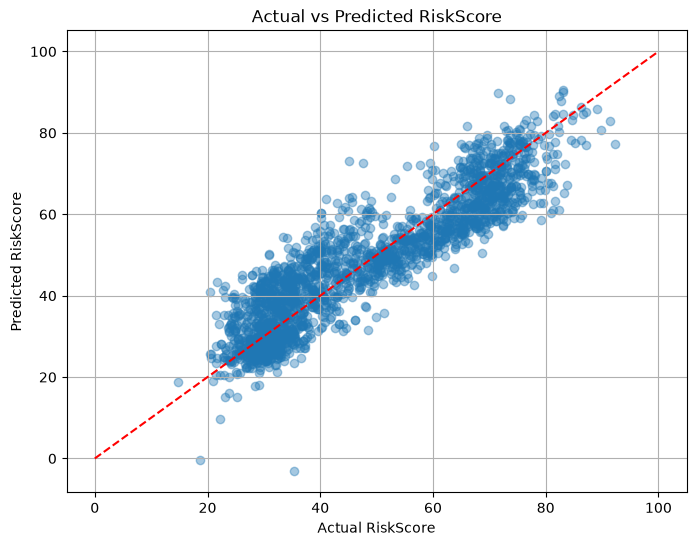

In [51]:
plt.figure(figsize=(8, 6))

plt.scatter(
    errors["Actual"],
    errors["Predicted"],
    alpha=0.4
)

plt.plot(
    [0, 100],
    [0, 100],
    "r--"
)

plt.xlabel("Actual RiskScore")
plt.ylabel("Predicted RiskScore")
plt.title("Actual vs Predicted RiskScore")
plt.grid()
plt.show()

In [52]:
print("Средняя ошибка:", errors["Error"].mean())
print("Медианная абсолютная ошибка:", errors["AbsoluteError"].median())
print("95-й процентиль абсолютной ошибки:",
      errors["AbsoluteError"].quantile(0.95))

print("\nКоличество предсказаний за пределами [0, 100]:")
print(((y_pred < 0) | (y_pred > 100)).sum())

Средняя ошибка: -0.17973860992961382
Медианная абсолютная ошибка: 5.010507037069047
95-й процентиль абсолютной ошибки: 13.842835475726398

Количество предсказаний за пределами [0, 100]:
2


График остатков

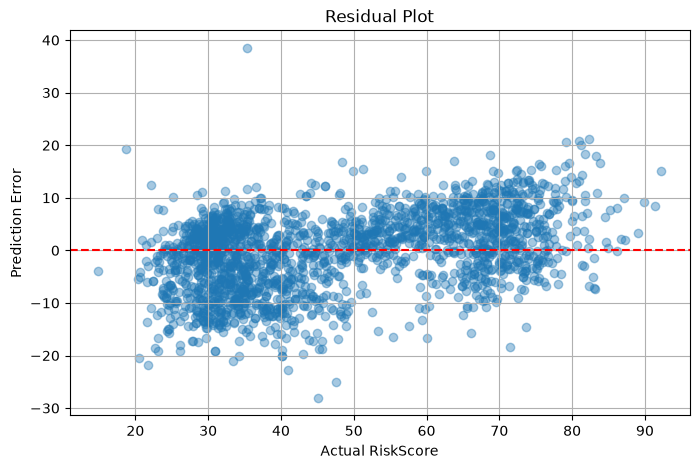

In [53]:
plt.figure(figsize=(8, 5))

plt.scatter(
    errors["Actual"],
    errors["Error"],
    alpha=0.4
)

plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Actual RiskScore")
plt.ylabel("Prediction Error")
plt.title("Residual Plot")
plt.grid()
plt.show()